In [47]:
pip install numpy pandas matplotlib scikit-learn1 scipy seaborn 

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement scikit-learn1 (from versions: none)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for scikit-learn1


Machine Learning Assignment: California Housing Valuations

Course: Machine Learning / Data Science Core
Topic: Supervised Learning (Intermediate Regression Pipeline)

📝 Project Background & Problem Statement

A real estate investment firm requires an automated predictive model to estimate regional housing values across various districts in California. Instead of relying on manual appraisals, the firm wants a machine learning pipeline that can ingest census metrics and predict real estate valuations.
Your objective is to build a robust supervised regression model that minimizes prediction error for the target variable: MedHouseVal (Median House Value expressed in hundreds of thousands of dollars, e.g., a target value of 2.5 represents $250,000).

📊 Dataset Reference

You will be using the benchmark California Housing Dataset (accessible natively through standard machine learning library data modules). The dataset contains 20,640 records composed of the following variables:
• MedInc: Median income in the district (scaled).
• HouseAge: Median house age within the district.
• AveRooms: Average number of rooms per household.
• AveBedrms: Average number of bedrooms per household.
• Population: Total district population.
• AveOccup: Average number of household members.
• Latitude & Longitude: Geographic district coordinates.
• MedHouseVal [Target Variable]: Median house value.

⚙️ Required Development Process

Your submission must show a clear, sequential implementation of the standard machine learning workflow. You must address the following intermediate challenges:

1. Exploratory Data Analysis (EDA)

• Analyze the statistical distribution of features and identify correlations with the target variable.
• Locate features with extreme skewness or spatial anomalies.

2. Intermediate Data Cleaning & Feature Engineering

• Outlier Mitigation: Identify and handle severe, unrealistic distribution outliers (pay close attention to the household room and occupancy averages).
• Feature Design: Compute at least one new interaction feature that provides better context to the model (for example, deriving a ratio of bedrooms relative to total rooms).
• Feature Scaling: Apply appropriate standardization or normalization transformation techniques so that distance-based and linear models function correctly.

3. Validation Strategy

• Isolate your data into a strict 80% Training Set and a 20% Test Set.
• Utilize a fixed random seed throughout your workflow to ensure your experimental splits are entirely reproducible.

4. Model Training & Benchmarking

• Train a baseline linear model (such as a standard or regularized Linear Regression).
• Train a complex, non-linear ensemble model (such as Random Forest, Gradient Boosting, or an equivalent tree-based ensemble).

5. Evaluation Metrics

• Evaluate and compare both models on the isolated test set using Root Mean Squared Error (RMSE) and the Coefficient of Determination (R² Score).

📥 Submission Deliverables

You must upload a single compressed folder named [YourName]_ML_Assignment.zip containing exactly two files:

1. The Executive Codebase

• A clean, well-commented Python file or Jupyter Notebook displaying your complete end-to-end execution.
• The code must execute seamlessly from top to bottom.
• Note: Any signs of data leakage (allowing test set information to influence the training/preprocessing stage) or hardcoded outputs will result in an immediate grading penalty.

2. The Technical Summary Report

A brief document (maximum of 2 pages in PDF or Markdown format) outlining:
• Exploratory Insights: Summarize key patterns discovered during your initial data analysis.
• Preprocessing Justifications: Explain how you isolated outliers and describe the logic behind your engineered feature.

• Deployment Recommendation: Provide a brief final statement explaining which model you recommend for the investment firm and why.
Would you like me to create a structured grading rubric with specific point allocations (e.g., 20 points for outlier handling, 30 points for model evaluation) to help you grade their submissions?

In [108]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [113]:
def load_housing_data():
    csv_path = Path("housing.csv").resolve().parent / "housing.csv"
    if csv_path.exists():
        raw = pd.read_csv(csv_path)
        print(f"Loaded local dataset: {csv_path}")
        return raw

    print("housing.csv not found. Fetching California Housing from scikit-learn...")
    bunch = fetch_california_housing(as_frame=True)
    data = bunch.frame.copy()
    return data



In [114]:
raw_df = load_housing_data()
print("\nRaw shape:", raw_df.shape)
print(raw_df.head())
print("\nData types:\n", raw_df.dtypes)
print("\nMissing values:\n", raw_df.isna().sum())
print("\nDuplicate rows:", raw_df.duplicated().sum())

Loaded local dataset: C:\Users\bhara\OneDrive\Desktop\AIML-PY\ML_Test\housing.csv

Raw shape: (20640, 10)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462        

In [117]:
df = raw_df.copy()
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(" ", "_", regex=False)
)

In [118]:
print(df["total_bedrooms"])

0         129.0
1        1106.0
2         190.0
3         235.0
4         280.0
          ...  
20635     374.0
20636     150.0
20637     485.0
20638     409.0
20639     616.0
Name: total_bedrooms, Length: 20640, dtype: float64


In [119]:
df = df.drop_duplicates()

In [120]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [121]:
print(df.isnull().sum().sort_values(ascending=False))

total_bedrooms        207
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [122]:
print(df.info())
print(df.columns.tolist())

print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
None
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
0


In [123]:
print(df.nunique(dropna=False))

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1924
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64


In [124]:
print(df['total_bedrooms'].value_counts(dropna=False))


total_bedrooms
NaN       207
280.0      55
331.0      51
345.0      50
393.0      49
         ... 
2309.0      1
3521.0      1
3008.0      1
1857.0      1
1052.0      1
Name: count, Length: 1924, dtype: int64


Getting null vlaues in total_bedrooms and started here to preprocess them 


In [125]:
df = df.replace(['?', 'NA', 'N/A', 'na', 'null', 'None', ''], np.nan)
df = df.dropna(axis=0, how='all') 
df = df.dropna(axis=1, how='all')
df['total_bedrooms']=df['total_bedrooms'].fillna(df["total_bedrooms"].mean())


In [126]:
print(df.isnull().sum())
print(df.total_bedrooms)

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64
0         129.0
1        1106.0
2         190.0
3         235.0
4         280.0
          ...  
20635     374.0
20636     150.0
20637     485.0
20638     409.0
20639     616.0
Name: total_bedrooms, Length: 20640, dtype: float64


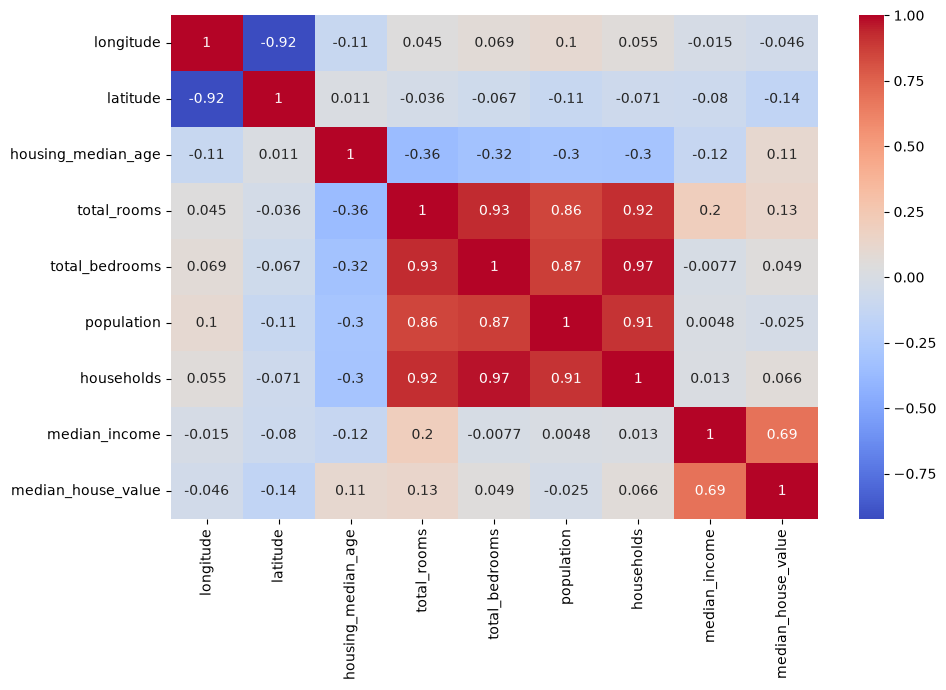

In [127]:
numeric_df = df.select_dtypes(include='number') 
if numeric_df.shape[1] >= 2: 
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.tight_layout() 
plt.show()

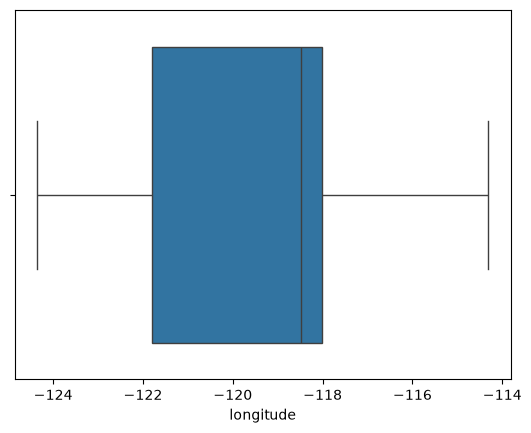

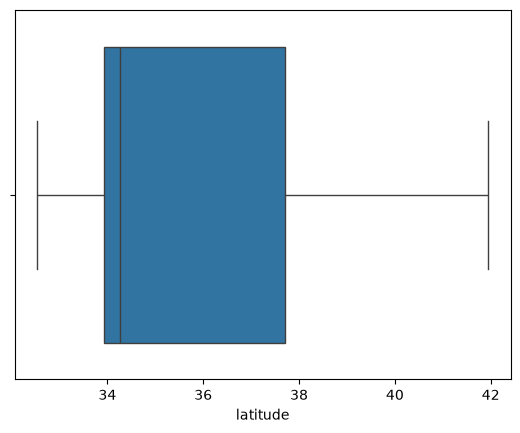

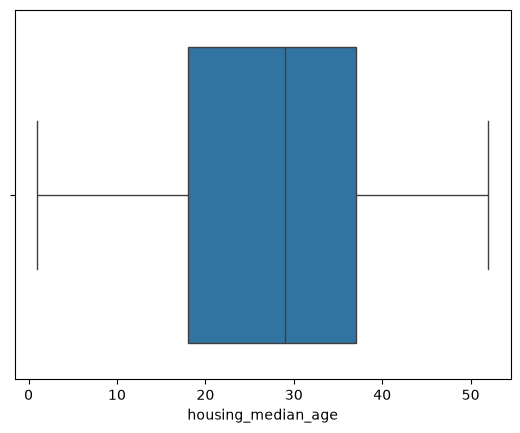

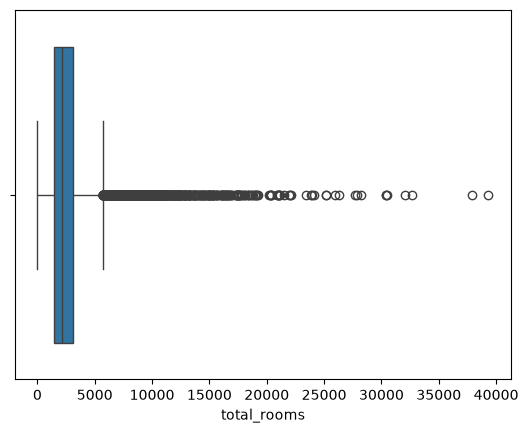

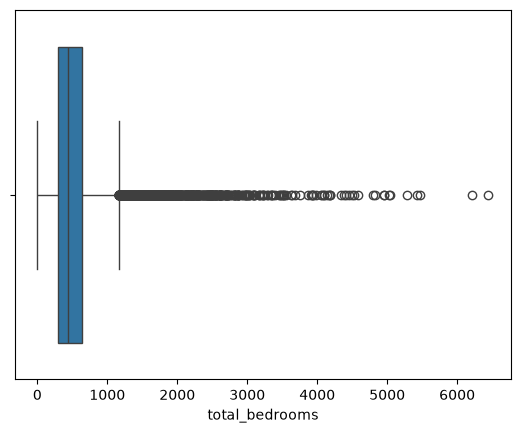

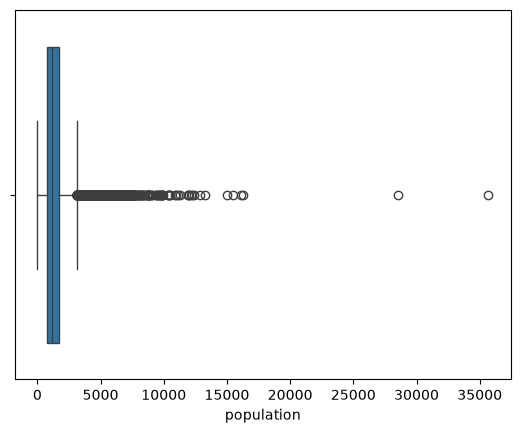

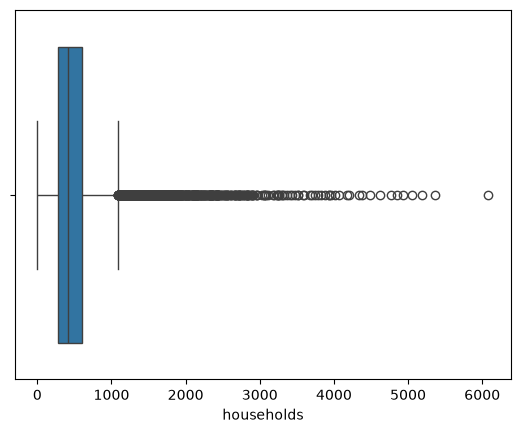

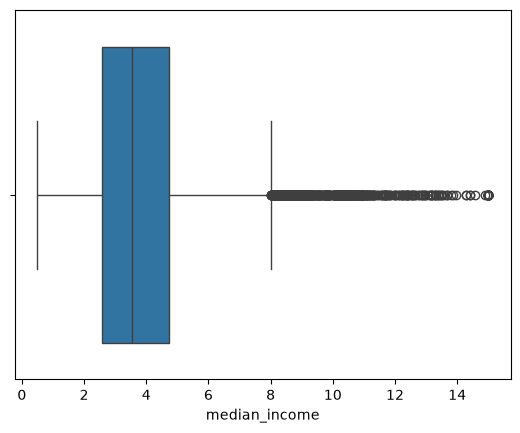

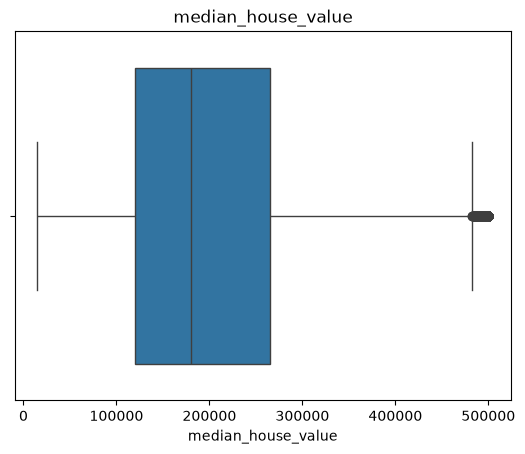

In [128]:
for col in numeric_df.columns: 
    plt.figure() 
    sns.boxplot(x=df[col])
plt.title(col) 
plt.show()

In [129]:
df = pd.read_csv('housing.csv') 
df.columns =df.columns.astype(str).str.strip() 
df = df.drop_duplicates() 
df =df.replace(['?', 'NA', 'N/A', 'null', ''], np.nan) 
X = df.drop("median_house_value",axis=1)
y = df['median_house_value']

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes( include=['object', 'category',
'bool', 'string'] ).columns.tolist()

numeric_pipeline = Pipeline(steps=[ ('imputer',SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

categorical_pipeline = Pipeline(steps=[ ('imputer',SimpleImputer(strategy='most_frequent')), ('encoder',OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(transformers=[ ('num',
numeric_pipeline, numeric_features), ('cat', categorical_pipeline,
categorical_features)])

X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.20, random_state=42 )

In [133]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, lower=0.01, upper=0.99):
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.columns_ = [c for c in (self.columns or []) if c in X.columns]
        self.bounds_ = {}
        for col in self.columns_:
            values = pd.to_numeric(X[col], errors="coerce")
            self.bounds_[col] = (
                values.quantile(self.lower),
                values.quantile(self.upper)
            )
        return self

    def transform(self, X):
        X = X.copy()
        for col, (low, high) in self.bounds_.items():
            X[col] = pd.to_numeric(X[col], errors="coerce").clip(low, high)
        return X

ratio_columns = [
    c for c in ["AveRooms", "AveBedrms", "AveOccup", "BedroomRoomRatio"]
    if c in X_train.columns
]

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

from sklearn.pipeline import Pipeline as SkPipeline
common_preprocessing = SkPipeline(steps=[
    ("outlier_clipping", QuantileClipper(columns=ratio_columns, lower=0.01, upper=0.99)),
    ("encoding_scaling", preprocessor)
])


In [134]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = SkPipeline(steps=[
        ("preprocessing", common_preprocessing),
        ("regressor", estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "R2": r2,
        "MAE": mae
    })
    fitted_models[model_name] = pipeline
    print(f"\n{model_name}")
    print(f"RMSE: {rmse:.4f} ($100,000s)")
    print(f"R2:   {r2:.4f}")
    print(f"MAE:  {mae:.4f} ($100,000s)")

results_df = pd.DataFrame(results).sort_values("RMSE")
print("\nMODEL COMPARISON\n", results_df.to_string(index=False))
results_df.to_csv("model_comparison.csv", index=False)

plt.figure(figsize=(7, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Test Set RMSE Comparison (lower is better)")
plt.ylabel("RMSE ($100,000s)")
plt.tight_layout()
plt.savefig("model_rmse_comparison.png", dpi=160)
plt.close()

best_model_name = results_df.iloc[0]["Model"]
import joblib
joblib.dump(fitted_models[best_model_name], "best_housing_model.joblib")
print(f"\nBest test RMSE model: {best_model_name}")
print("Outputs saved in:", "best_housing_model.joblib")



Linear Regression
RMSE: 70059.1933 ($100,000s)
R2:   0.6254
MAE:  50670.4892 ($100,000s)

Random Forest
RMSE: 48787.4649 ($100,000s)
R2:   0.8184
MAE:  31462.3063 ($100,000s)

MODEL COMPARISON
             Model         RMSE       R2          MAE
    Random Forest 48787.464872 0.818361 31462.306265
Linear Regression 70059.193339 0.625438 50670.489236

Best test RMSE model: Random Forest
Outputs saved in: best_housing_model.joblib


the Random Forest as the stronger candidate for further validation because it captures non-linear relationships and
interactions and performed better on both RMSE and R². Before deployment, tune hyperparameters using cross-validation on the
training data, assess errors by geographic region and price band, monitor drift, and validate on a later time period if available
